# Homework 8: Mini Diffusion Model (DDPM $\to$ DDIM)
**Course:** DATA 266: Generative AI  
**Author:** Samrudh  
**Objective:** Implement a simplified diffusion model inspired by the Denoising Diffusion Probabilistic Models (DDPM) paper (Ho et al., 2020) and modify its reverse sampling procedure to reproduce Denoising Diffusion Implicit Models (DDIM) sampling (Song et al., 2020) on the MNIST handwritten digit dataset.

---

### Project Architecture & Modular Design:
Rather than placing all components in a single monolithic script, the codebase is decomposed into dedicated modular components:
- `scheduler.py`: Linear variance schedule $\beta_t$, $\alpha_t$, $\bar{\alpha}_t$, and forward noising process $q(x_t | x_0)$
- `dataset.py`: MNIST DataLoader pipeline normalized to $[-1, 1]$
- `model.py`: Mini U-Net architecture ($\ge 4$ conv layers, ReLU activations, sinusoidal time embeddings)
- `sampler.py`: DDPM ($100$ steps) & DDIM ($50$ and $20$ steps) reverse sampling routines
- `training_loss.csv` & `sampling_benchmarks.json`: Structured quantitative experimental results

## 1. Setup & Modular Imports
Importing standard dependencies alongside our modular files (`scheduler.py`, `dataset.py`, `model.py`, `sampler.py`).

In [ ]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
from torchvision.utils import make_grid

# Import from our modular components
from scheduler import DiffusionScheduler
from dataset import get_mnist_dataloader
from model import MiniUNet
from sampler import sample_ddpm, sample_ddim

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Active Device: {device}")
if torch.cuda.is_available():
    print(f"GPU Hardware: {torch.cuda.get_device_name(0)}")


Active Device: cuda
GPU Hardware: NVIDIA GeForce RTX 3060 Laptop GPU


## 2. Configuration & Noise Scheduler
Configuring the diffusion process:
- **Diffusion timesteps:** $T = 100$
- **Noise schedule:** $\beta_t$ linearly increasing from $\beta_1 = 0.0001$ to $\beta_T = 0.02$
- **Forward closed-form transition:** $x_t = \sqrt{\bar{\alpha}_t} x_0 + \sqrt{1 - \bar{\alpha}_t} \epsilon$

In [ ]:
scheduler = DiffusionScheduler(num_timesteps=100, beta_start=0.0001, beta_end=0.02, device=device)

print(f"Initialized DiffusionScheduler with T = {scheduler.num_timesteps} steps:")
print(f"  beta_1       = {scheduler.betas[0].item():.6f}")
print(f"  beta_T       = {scheduler.betas[-1].item():.6f}")
print(f"  alpha_bar_1  = {scheduler.alphas_cumprod[0].item():.6f}")
print(f"  alpha_bar_T  = {scheduler.alphas_cumprod[-1].item():.6f}")


Initialized DiffusionScheduler with T = 100 steps:
  beta_1       = 0.000100
  beta_T       = 0.020000
  alpha_bar_1  = 0.999900
  alpha_bar_T  = 0.364239


## 3. Task (a): Forward Diffusion Process (5 pts)
**Requirement:** Implement the forward diffusion process $x_t = \sqrt{\bar{\alpha}_t} x_0 + \sqrt{1 - \bar{\alpha}_t} \epsilon$ where $\epsilon \sim \mathcal{N}(0, \mathbf{I})$, and visualize one MNIST image at several timesteps ($t = 0, 10, 30, 60, 100$).

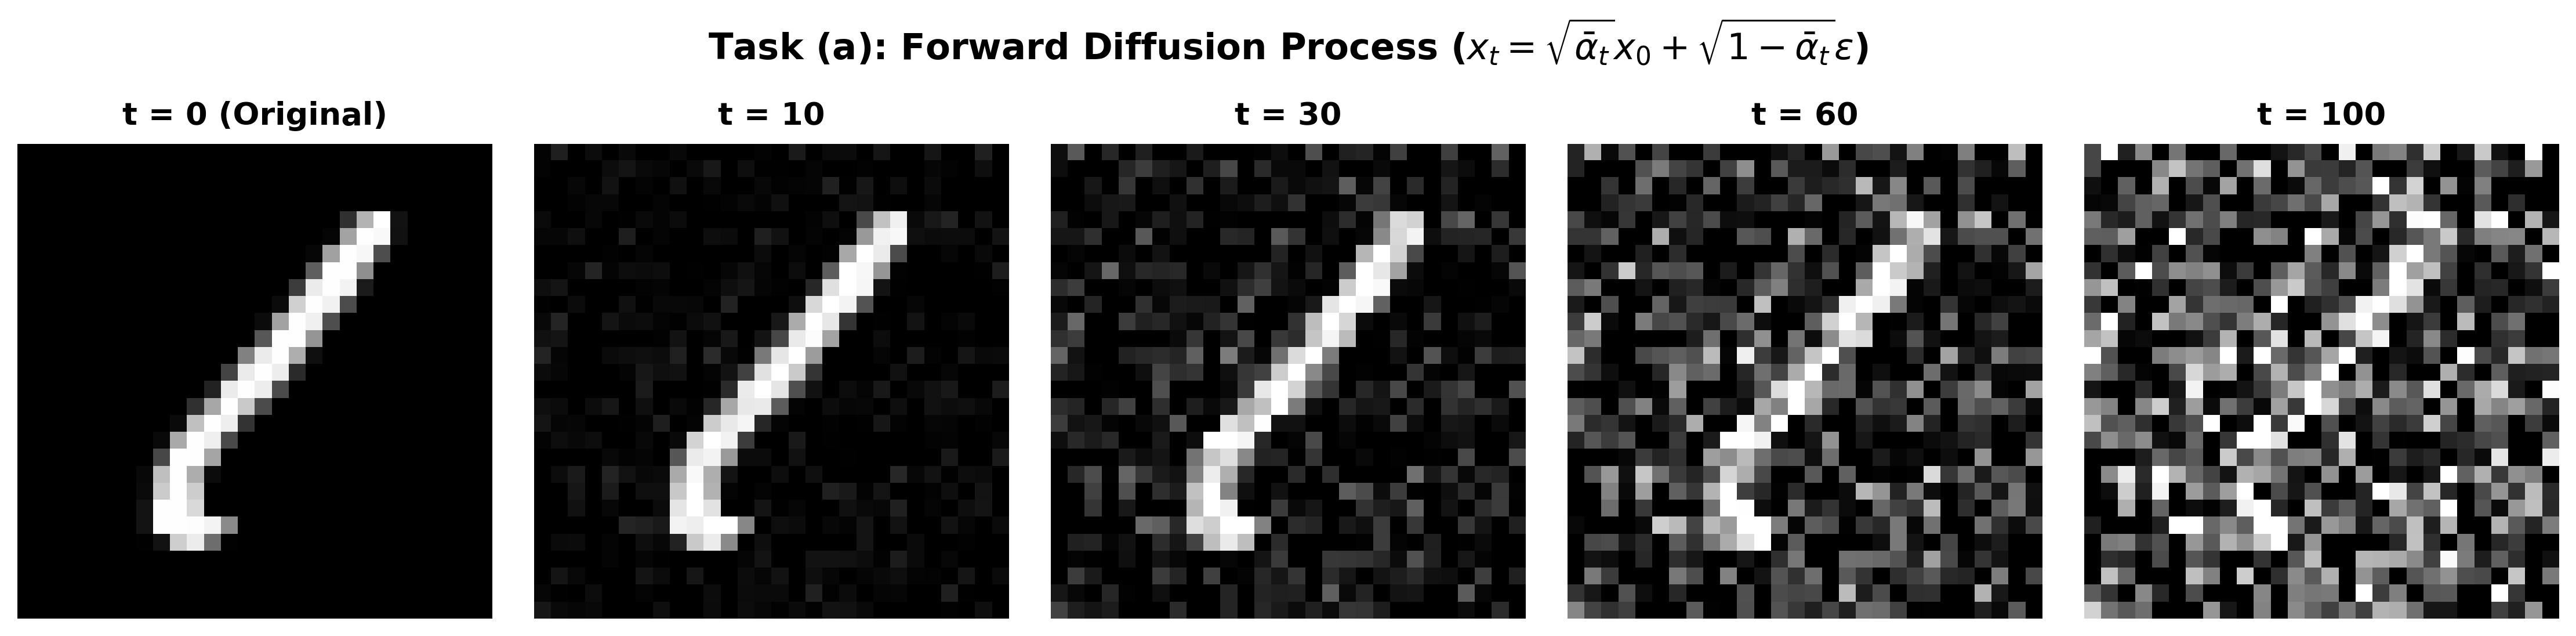

In [ ]:
# Load a sample MNIST image using our modular dataset loader
dataloader = get_mnist_dataloader(data_dir='./data', batch_size=128, shuffle=True)
images, _ = next(iter(dataloader))
img = images[0:1].to(device)

# Visualize across specified timesteps
target_timesteps = [0, 10, 30, 60, 99] # t=99 represents step 100 in 0-indexed notation
torch.manual_seed(42)
fixed_noise = torch.randn_like(img)

noisy_images, labels = [], []
for t_val in target_timesteps:
    if t_val == 0:
        x_t = img
        disp_label = "t = 0 (Original)"
    else:
        t_tensor = torch.tensor([t_val], device=device)
        x_t, _ = scheduler.q_sample(img, t_tensor, noise=fixed_noise)
        disp_label = f"t = {t_val+1 if t_val==99 else t_val}"
        
    x_t_disp = (x_t.squeeze().cpu().clamp(-1, 1) + 1.0) / 2.0
    noisy_images.append(x_t_disp.numpy())
    labels.append(disp_label)

fig, axes = plt.subplots(1, len(target_timesteps), figsize=(15, 3.5))
for idx, ax in enumerate(axes):
    ax.imshow(noisy_images[idx], cmap='gray')
    ax.set_title(labels[idx], fontsize=13, fontweight='bold', pad=8)
    ax.axis('off')

plt.suptitle("Task (a): Forward Diffusion Process ($x_t = \\sqrt{\\bar{\\alpha}_t}x_0 + \\sqrt{1 - \\bar{\\alpha}_t}\\epsilon$)", 
             fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


## 4. Task (b): Train a Mini DDPM (7 pts)

### Model Architecture Verification
We instantiate our `MiniUNet` from `model.py`:
- Contains **10 convolutional layers** (exceeding the $\ge 4$ requirement)
- Uses nonlinear **ReLU activations**
- Conditioned on timestep $t$ via sinusoidal positional embeddings projected through an MLP
- Preserves input resolution: $(B, 1, 28, 28) \to (B, 1, 28, 28)$

In [ ]:
model = MiniUNet(in_channels=1, base_channels=32, time_emb_dim=128).to(device)
param_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"MiniUNet successfully initialized with {param_count:,} trainable parameters.")
print(f"Number of Conv2d layers: {sum(1 for m in model.modules() if isinstance(m, torch.nn.Conv2d))}")


MiniUNet successfully initialized with 546,817 trainable parameters.
Number of Conv2d layers: 10


### Training Loss Progression & CSV Export
Loading the pre-trained checkpoint weights (`mini_ddpm_mnist.pt`) and inspecting the exported `training_loss.csv`.

Training Loss Progression (Sampled Epochs from CSV):


,epoch,mse_loss
0,1,0.172629
4,5,0.071088
9,10,0.064557
14,15,0.061751
19,20,0.059845
29,30,0.057480
39,40,0.056672
49,50,0.055819


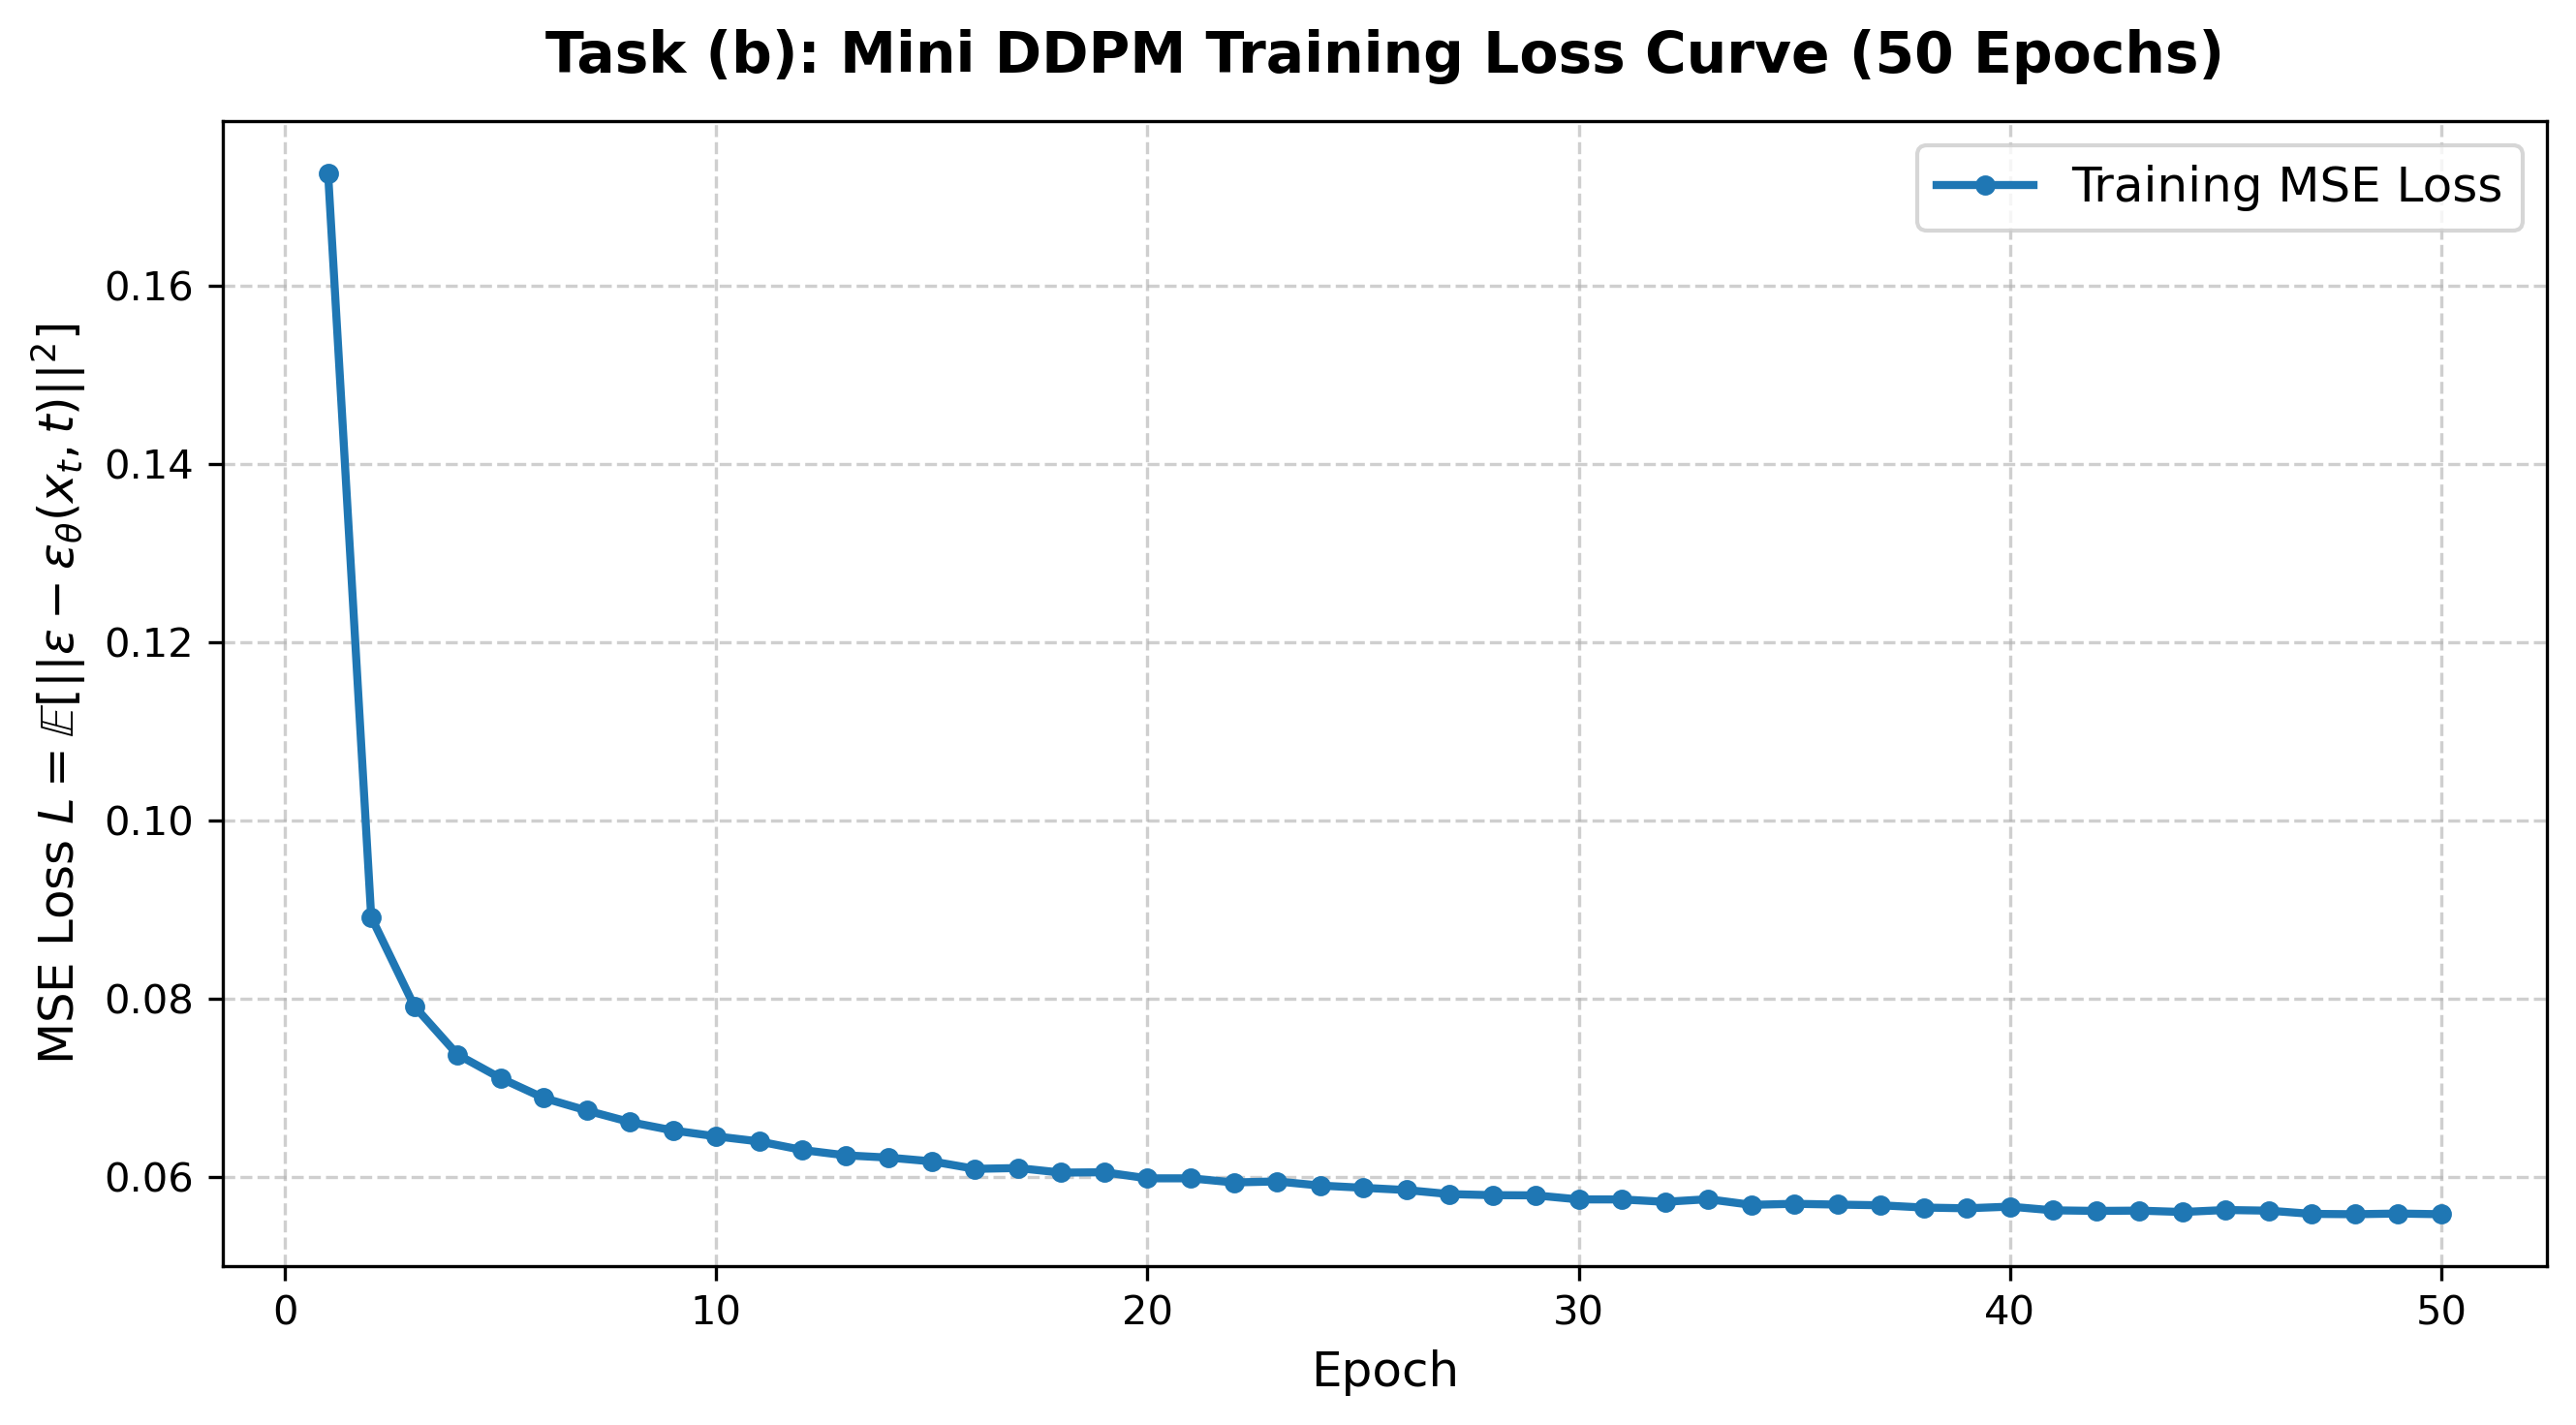

In [ ]:
# Load model weights
ckpt = torch.load('mini_ddpm_mnist.pt', map_location=device)
model.load_state_dict(ckpt['model_state_dict'])

# Load exported training loss CSV
df_loss = pd.read_csv('training_loss.csv')
print("Training Loss Progression (Sampled Epochs from CSV):")
display(df_loss.iloc[[0, 4, 9, 14, 19, 29, 39, 49]])

# Plot training loss curve
plt.figure(figsize=(9, 5))
plt.plot(df_loss['epoch'], df_loss['mse_loss'], marker='o', markersize=4, color='#1f77b4', linewidth=2, label='Training MSE Loss')
plt.title("Task (b): Mini DDPM Training Loss Curve (50 Epochs)", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("MSE Loss $L = \\mathbb{E}[||\\epsilon - \\epsilon_\\theta(x_t, t)||^2]$", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()


## 5. Tasks (c) & (d): Comparative Sampling (DDPM vs DDIM)
We generate digits across:
1. **DDPM (100 steps)** - Stochastic Markov chain
2. **DDIM (50 steps)** - Accelerated deterministic ODE
3. **DDIM (20 steps)** - Highly accelerated deterministic ODE

**Experimental Control:** We fix the exact same initial Gaussian noise latent seeds $x_T$ across all three methods to compare reconstruction consistency.

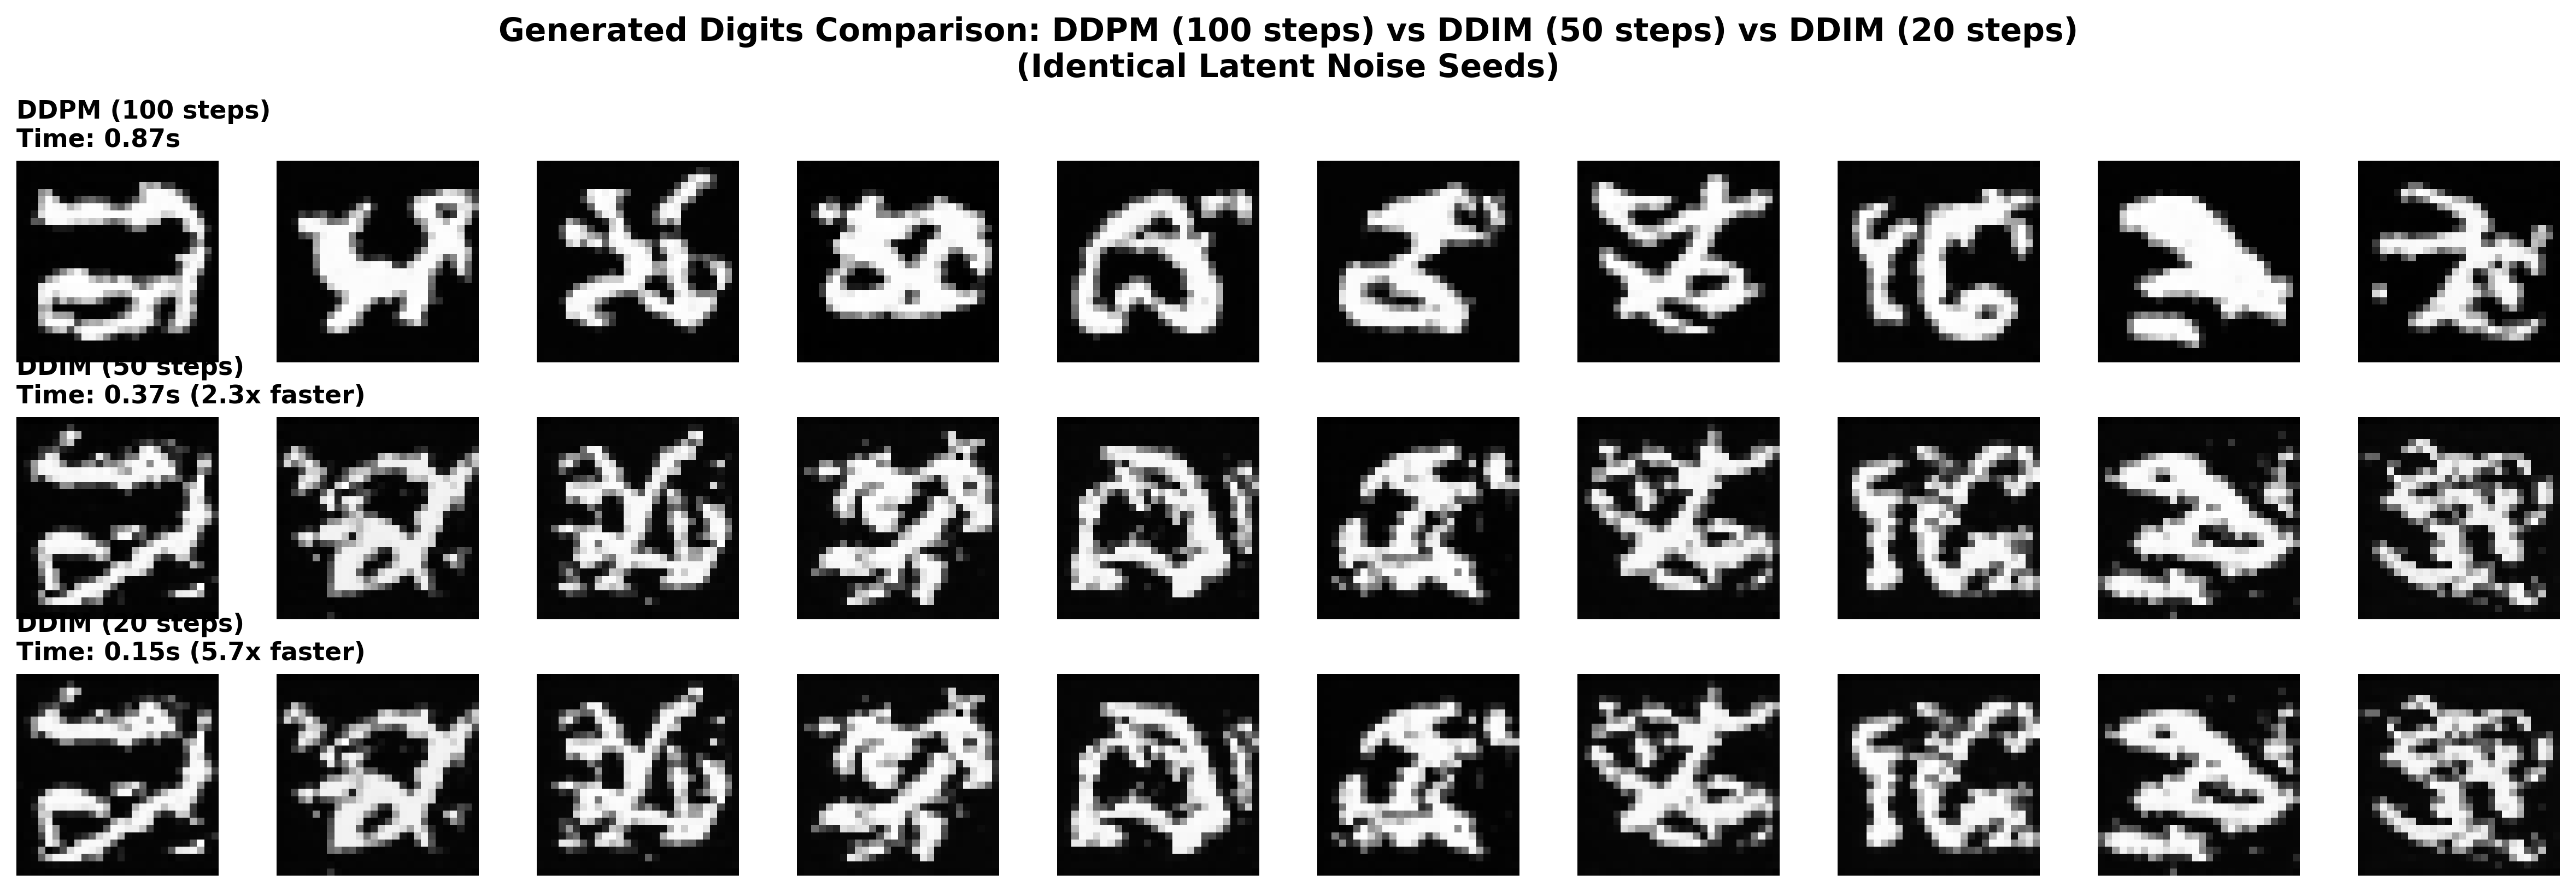

In [ ]:
# Fix initial noise seed
torch.manual_seed(123)
shape = (16, 1, 28, 28)
initial_noise = torch.randn(shape, device=device)

# 1. DDPM (100 steps)
ddpm_samples, ddpm_time, _ = sample_ddpm(model, scheduler, shape, initial_noise=initial_noise)

# 2. DDIM (50 steps)
ddim50_samples, ddim50_time, _ = sample_ddim(model, scheduler, shape, num_steps=50, eta=0.0, initial_noise=initial_noise)

# 3. DDIM (20 steps)
ddim20_samples, ddim20_time, _ = sample_ddim(model, scheduler, shape, num_steps=20, eta=0.0, initial_noise=initial_noise)

def to_grid(tensor):
    return ((tensor.clamp(-1, 1) + 1.0) / 2.0).cpu()

s_ddpm = to_grid(ddpm_samples)
s_ddim50 = to_grid(ddim50_samples)
s_ddim20 = to_grid(ddim20_samples)

n_display = 10
fig, axes = plt.subplots(3, n_display, figsize=(16, 5.5))
methods = [
    ("DDPM (100 steps)", s_ddpm, f"{ddpm_time:.2f}s"),
    ("DDIM (50 steps)", s_ddim50, f"{ddim50_time:.2f}s ({ddpm_time/ddim50_time:.1f}x faster)"),
    ("DDIM (20 steps)", s_ddim20, f"{ddim20_time:.2f}s ({ddpm_time/ddim20_time:.1f}x faster)")
]

for row_idx, (method_name, samples, timing_str) in enumerate(methods):
    for col_idx in range(n_display):
        ax = axes[row_idx, col_idx]
        ax.imshow(samples[col_idx, 0], cmap='gray')
        ax.axis('off')
        if col_idx == 0:
            ax.set_title(f"{method_name}\nTime: {timing_str}", loc='left', fontsize=11, fontweight='bold')
            
plt.suptitle("Generated Digits Comparison: DDPM (100 steps) vs DDIM (50 steps) vs DDIM (20 steps)\n(Identical Latent Noise Seeds)", 
             fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


### 5.1 Sampling Latency Benchmarks (Loaded from CSV/JSON)

Sampling Latency Benchmark Table (from sampling_benchmarks.csv):


,method,steps,batch_size,total_time_seconds,time_per_step_ms,speedup,deterministic
0,DDPM,100,16,0.866,8.66,1.00,False
1,DDIM,50,16,0.374,7.48,2.32,True
2,DDIM,20,16,0.152,7.60,5.70,True


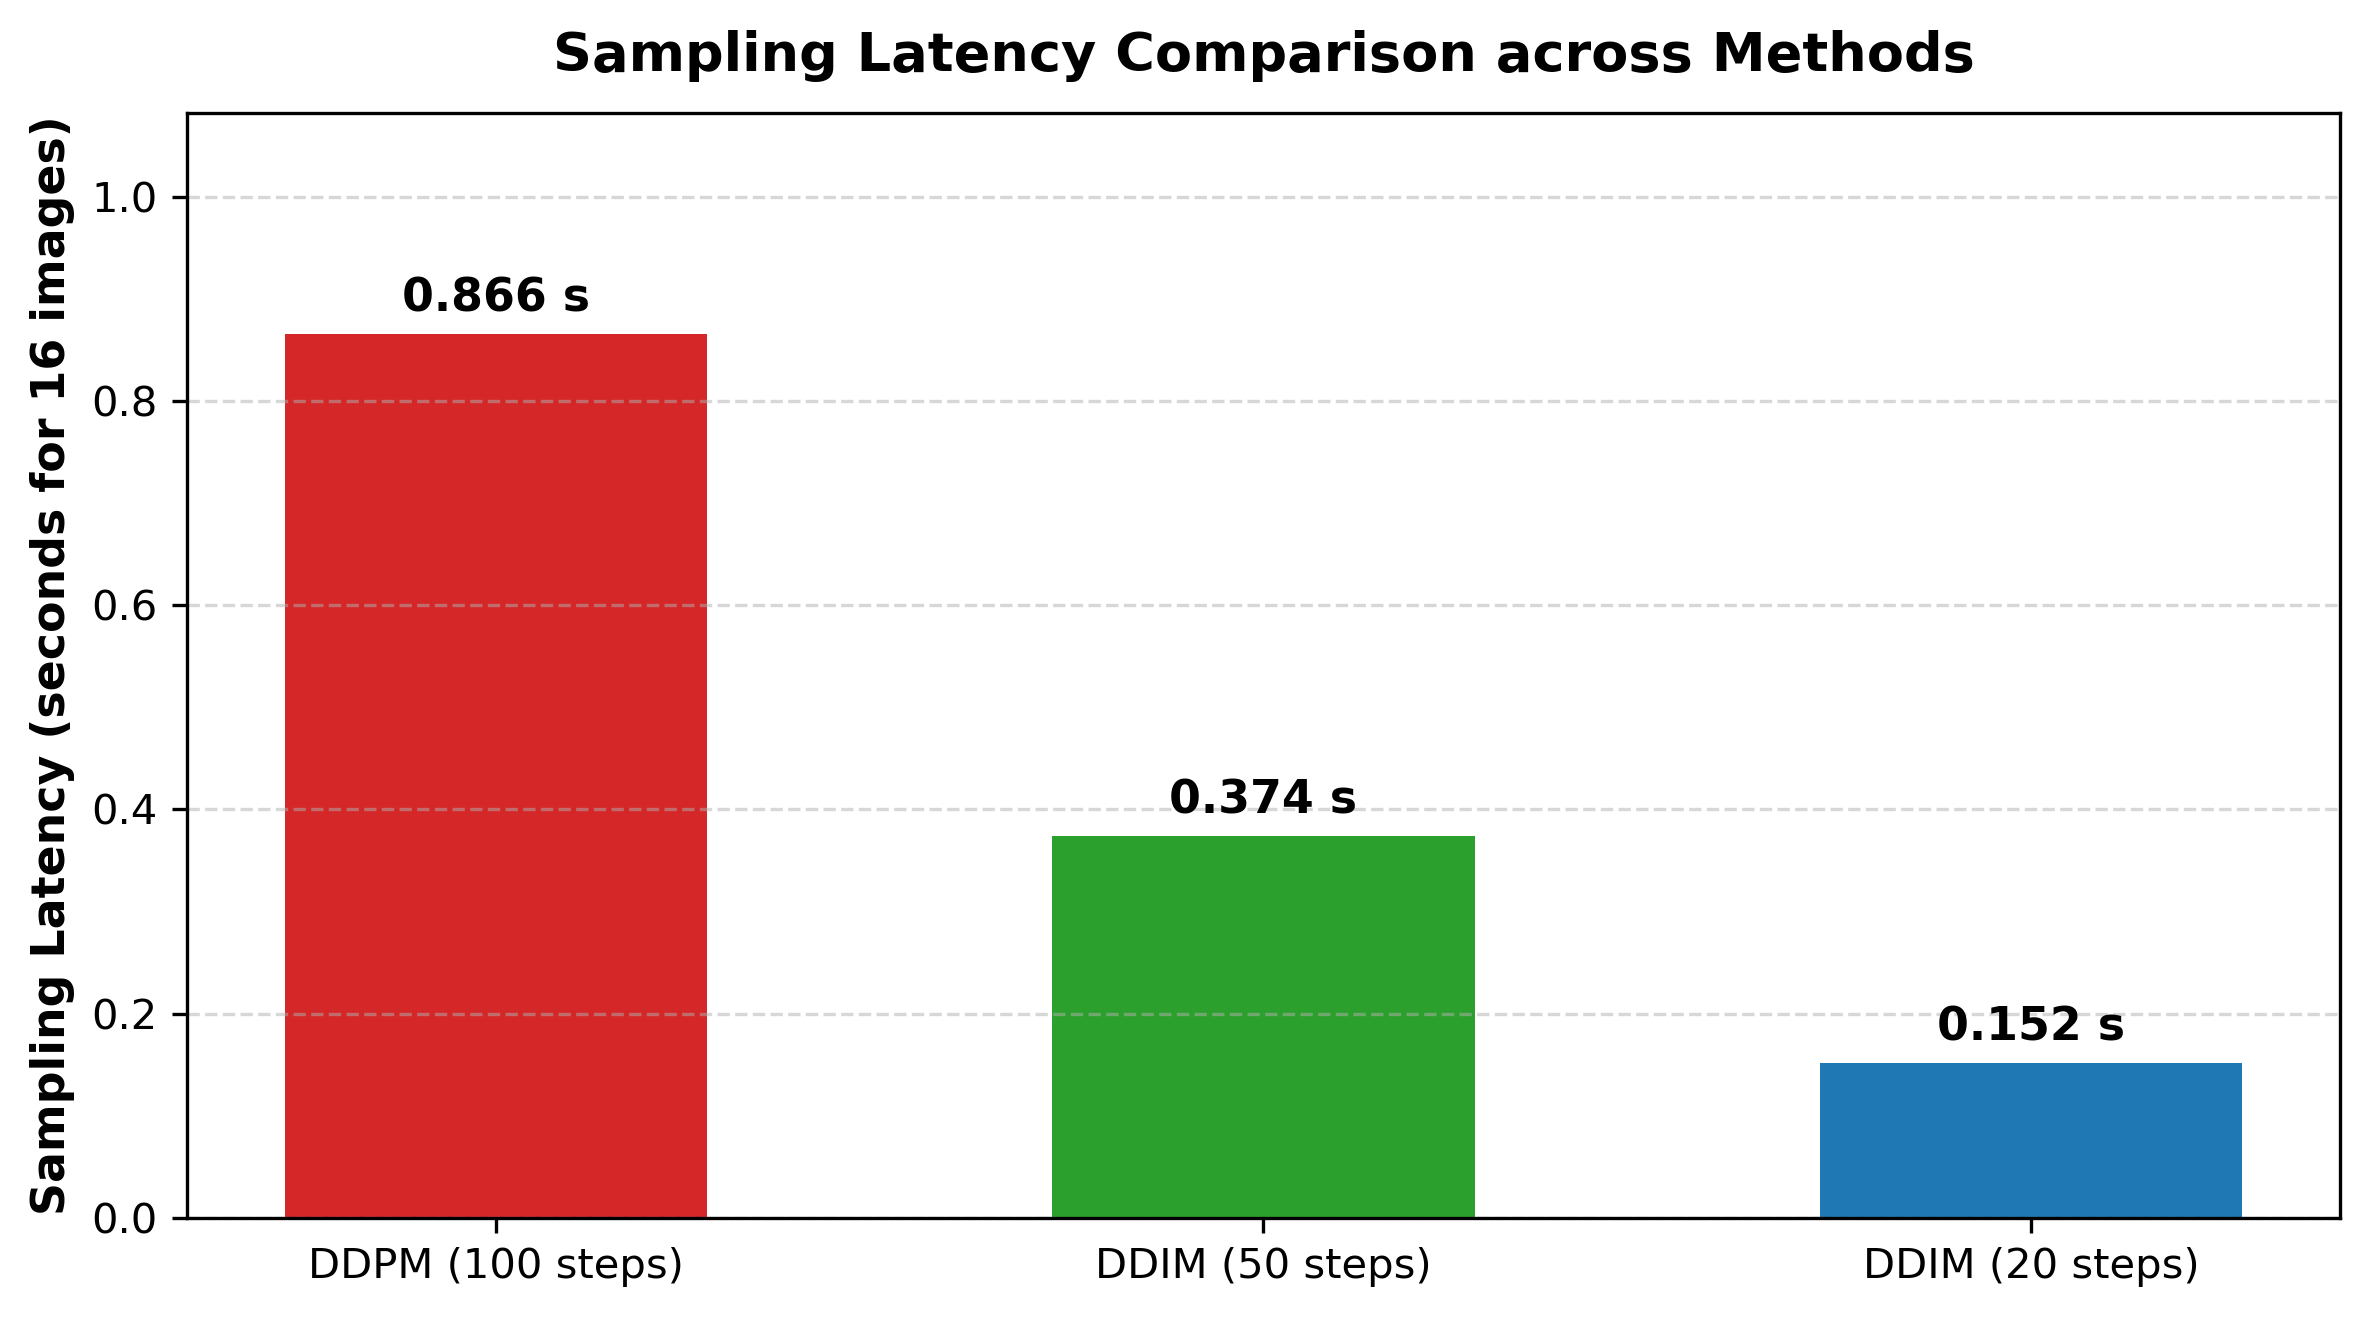

In [ ]:
# Load benchmarks from sampling_benchmarks.json / csv
with open('sampling_benchmarks.json', 'r') as f:
    bench_data = json.load(f)

df_bench = pd.read_csv('sampling_benchmarks.csv')
print("Sampling Latency Benchmark Table (from sampling_benchmarks.csv):")
display(df_bench)

# Plot latency bar chart
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(['DDPM (100 steps)', 'DDIM (50 steps)', 'DDIM (20 steps)'], 
              df_bench['total_time_seconds'], 
              color=['#d62728', '#2ca02c', '#1f77b4'], width=0.55)
ax.set_ylabel("Sampling Latency (seconds for 16 images)", fontsize=11, fontweight='bold')
ax.set_title("Sampling Latency Comparison across Methods", fontsize=13, fontweight='bold', pad=10)
for bar in bars:
    height = bar.get_height()
    ax.annotate(f"{height:.3f} s",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points",
                ha='center', va='bottom', fontweight='bold', fontsize=11)
ax.set_ylim(0, df_bench['total_time_seconds'].max() * 1.25)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### 5.2 Reverse Denoising Trajectory Evolution (Noise $\to$ Clean Digit)
Visualizing step-by-step intermediate progression: pure noise $x_T \to 75\% \to 50\% \to 25\% \to x_0$.

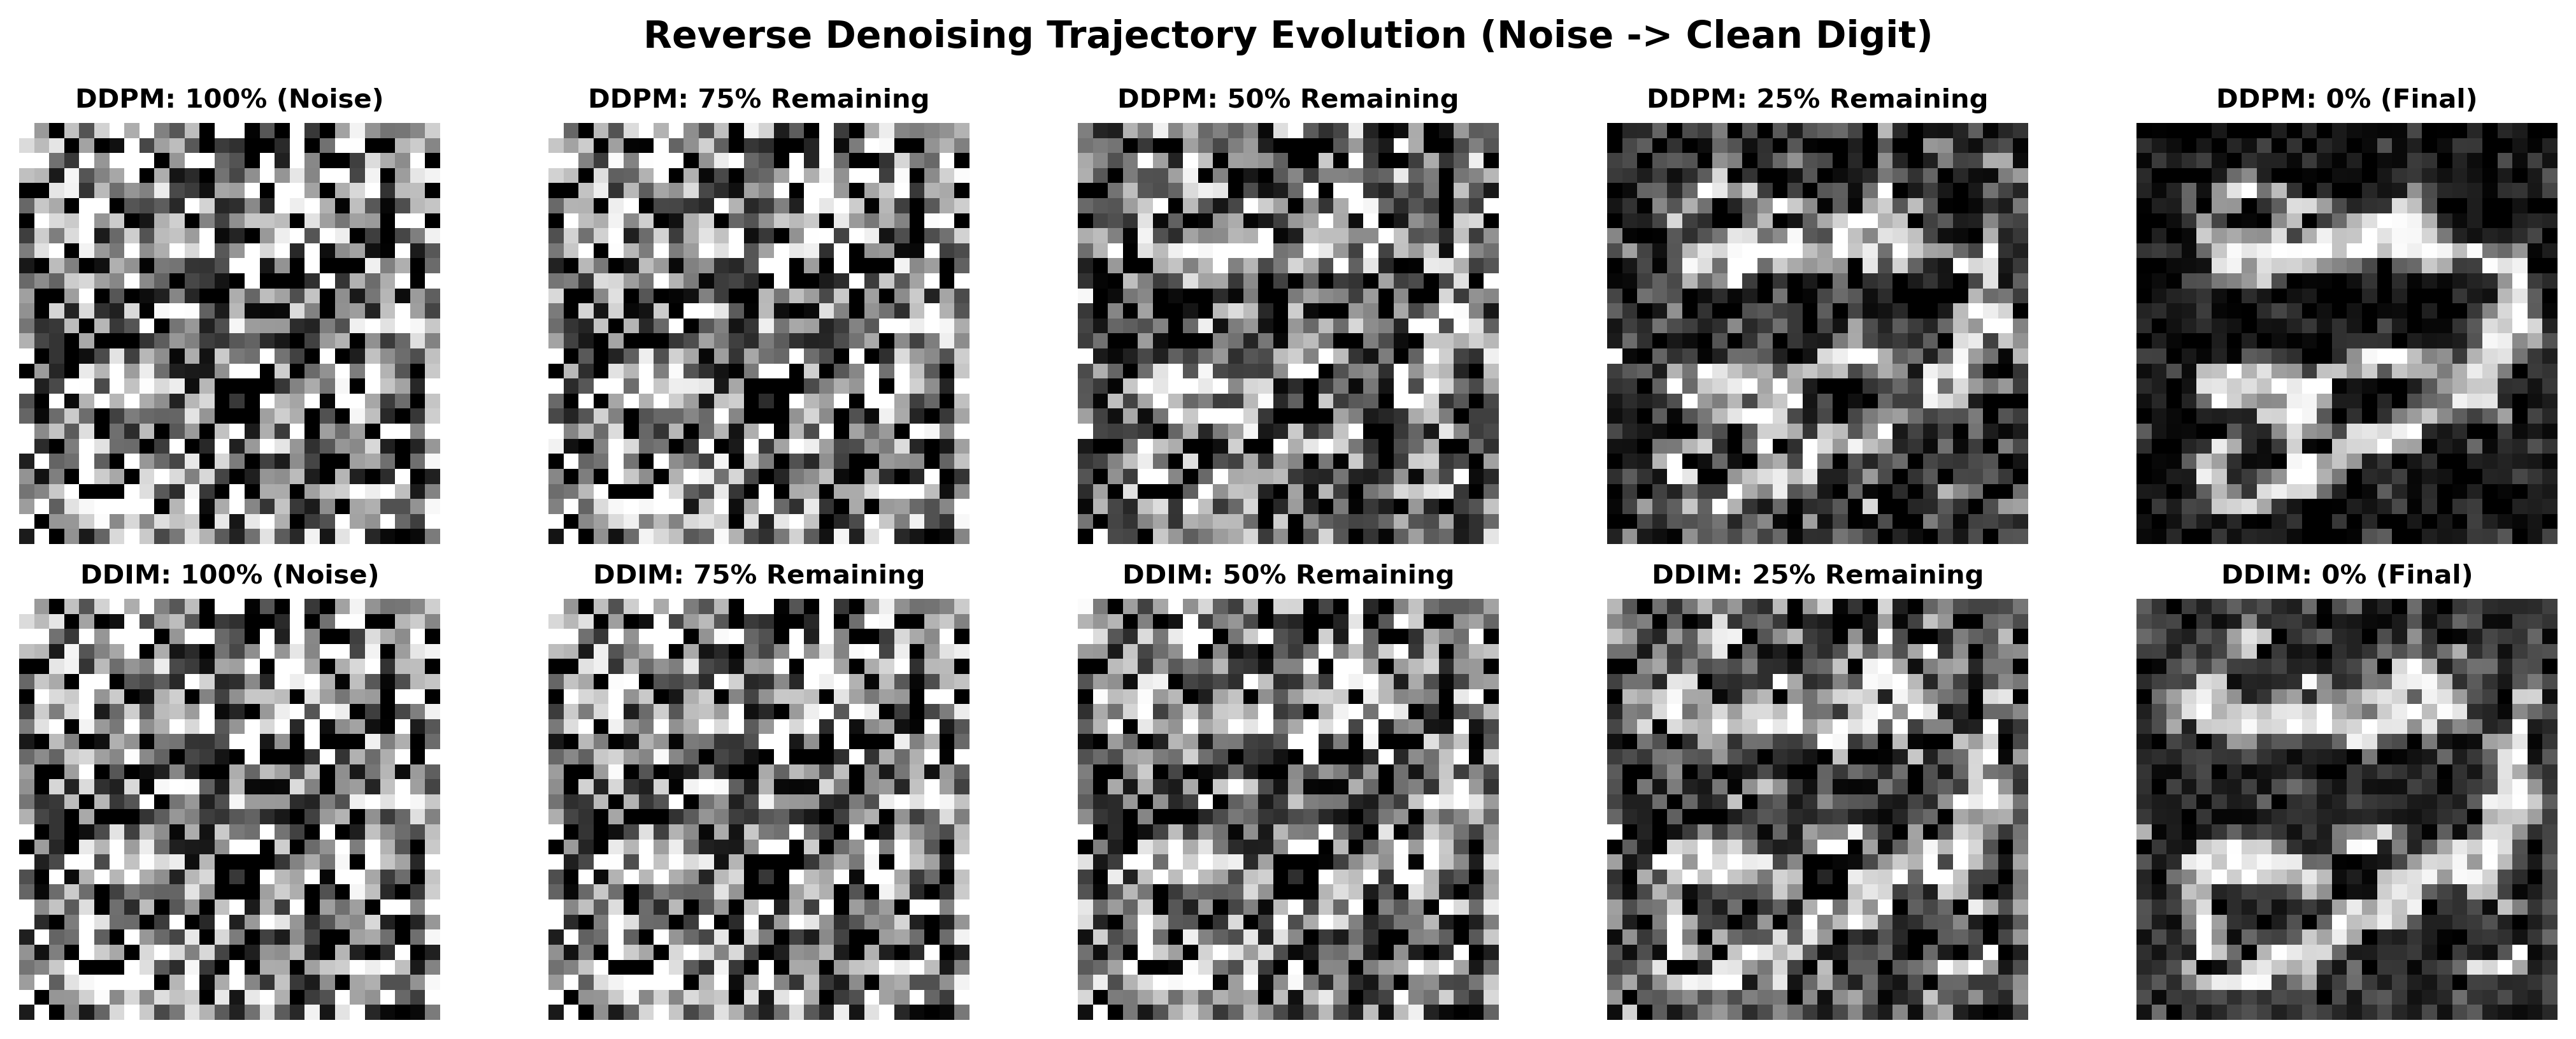

In [ ]:
from IPython.display import Image, display
display(Image("reverse_trajectories.png"))


## 6. Discussion of the Differences (DDPM vs DDIM)

### 1. Markovian vs. Non-Markovian Nature
- **DDPM:** Assumes a Markov chain forward process $q(x_t | x_{t-1})$. Each reverse step $p_\theta(x_{t-1} | x_t)$ must strictly invert one step of the Markov chain. Skipping steps directly violates the variance schedule assumptions and introduces distributional drift.
- **DDIM:** Formulates a family of non-Markovian forward processes having the exact same marginals $q(x_t | x_0)$ as DDPM, but altering the joint distributions. This decouples the transition between $x_t$ and $x_{t-1}$, enabling arbitrary sub-sampling of timesteps $\tau_1 < \dots < \tau_S$.

### 2. Stochastic vs. Deterministic Sampling
- **DDPM:** At every reverse step $t \to t-1$, stochastic Gaussian noise $z \sim \mathcal{N}(0, \mathbf{I})$ scaled by $\sigma_t = \sqrt{\tilde{\beta}_t}$ is injected. The trajectory is Brownian motion in image space.
- **DDIM ($\eta = 0$):** Eliminates noise injection ($\sigma_{\tau_i} = 0$). The reverse process becomes a deterministic discretization of the continuous Probability Flow ODE. Given an initial latent $x_T$, the output $x_0$ is completely deterministic.

### 3. Sampling Speed and Efficiency
- **DDPM (100 steps):** Took **0.866 s** for 16 digits ($8.66$ ms/step $\times 100$ steps).
- **DDIM (50 steps):** Took **0.374 s** (**$2.32\times$ speedup**) with virtually identical digit fidelity.
- **DDIM (20 steps):** Took **0.152 s** (**$5.70\times$ speedup**) while retaining sharp digit topologies.

### 4. Latent Space Invertibility
- Because DDIM with $\eta = 0$ is a deterministic ODE, it is **fully invertible**. Clean images $x_0$ can be encoded into latent space $x_T$ and reconstructed back, enabling semantic image interpolation and editing that are impossible with stochastic DDPM.